# Лабораторная работа №4: Байесовская сеть

## Цель

Научиться представлять зависимости между случайными величинами с помощью байесовской сети, самостоятельно строить структуру графа и выполнять вероятностный вывод при наличии дополнительной информации.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import pgmpy
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

# Выбор данных

Для работы выбран открытый датасет **COVID-19 dataset** (Kaggle, автор Meir Nizri).
https://www.kaggle.com/datasets/meirnizri/covid19-dataset
**Один объект** — это один пациент, поступивший в больницу с подтверждённым диагнозом COVID-19.
Каждая строка таблицы описывает пол, возраст, наличие сопутствующих заболеваний у пациента, а также исход его госпитализации (выжил или умер).

## Переменные и их смысл

| Переменная | Тип | Описание |
|---|---|---|
| `SEX` | бинарная | пол пациента (1 — женский, 2 — мужской) |
| `AGE` | непрерывная | возраст пациента в годах |
| `CLASIFFICATION_FINAL` | категориальная | итог COVID-теста (1–3 — диагноз COVID разной степени, 4 и выше — не носитель/неинформативный тест) |
| `PATIENT_TYPE` | бинарная | тип помощи: 1 — отправлен домой, 2 — госпитализирован |
| `PNEUMONIA` | бинарная | есть ли воспаление лёгочных альвеол (пневмония) |
| `PREGNANT` | бинарная | беременна ли пациентка (1 — да, 2 — нет) |
| `DIABETES` | бинарная | есть ли сахарный диабет |
| `COPD` | бинарная | есть ли хроническая обструктивная болезнь лёгких |
| `ASTHMA` | бинарная | есть ли бронхиальная астма |
| `INMSUPR` | бинарная | есть ли иммуносупрессия (ослабленный иммунитет) |
| `HIPERTENSION` | бинарная | есть ли артериальная гипертензия |
| `CARDIOVASCULAR` | бинарная | есть ли заболевания сердца или сосудов |
| `RENAL_CHRONIC` | бинарная | есть ли хроническая болезнь почек |
| `OTHER_DISEASE` | бинарная | есть ли другие заболевания |
| `OBESITY` | бинарная | есть ли ожирение |
| `TOBACCO` | бинарная | употребляет ли пациент табак |
| `USMER` | бинарная | обращался ли пациент в мед. учреждения первого/второго/третьего уровня |
| `MEDICAL_UNIT` | категориальная | тип учреждения национальной системы здравоохранения, оказавшего помощь |
| `INTUBED` | бинарная | подключался ли пациент к аппарату ИВЛ |
| `ICU` | бинарная | поступал ли пациент в отделение реанимации |
| `DATE_DIED` | дата/бинарная | дата смерти или признак того, что пациент выжил |

В булевых признаках `1` означает «да», `2` — «нет», а значения `97` и `99` — пропущенные данные.
Между признаками можно содержательно предположить причинно-следственные связи:

- **возраст предшествует болезням**: с возрастом растёт вероятность хронических заболеваний (диабет, гипертензия, болезни сердца и почек, ХОБЛ);
- **сопутствующие заболевания повышают риск осложнений**: например, диабет и болезни лёгких увеличивают вероятность пневмонии;
- **осложнения ведут к тяжёлому течению**: пневмония повышает шанс попадания в реанимацию, а в реанимации может потребоваться интубация;
- **возраст, тяжёлые заболевания и осложнения влияют на исход**: всё перечисленное увеличивает вероятность летального исхода.

# Подготовка данных
В исходном датасете 21 признак. Сначала исследуем пропущенные значения по всем столбцам, затем решим, какие признаки оставить в сети.

In [28]:
initData = pd.read_csv('Covid Data.csv')
for col in initData.columns:
    print(initData[col].value_counts())

USMER
2    662903
1    385672
Name: count, dtype: int64
MEDICAL_UNIT
12    602995
4     314405
6      40584
9      38116
3      19175
8      10399
10      7873
5       7244
11      5577
13       996
7        891
2        169
1        151
Name: count, dtype: int64
SEX
1    525064
2    523511
Name: count, dtype: int64
PATIENT_TYPE
1    848544
2    200031
Name: count, dtype: int64
DATE_DIED
9999-99-99    971633
06/07/2020      1000
07/07/2020       996
13/07/2020       990
16/06/2020       979
               ...  
27/03/2021         1
31/03/2021         1
02/04/2021         1
13/04/2021         1
22/04/2021         1
Name: count, Length: 401, dtype: int64
INTUBED
97    848544
2     159050
1      33656
99      7325
Name: count, dtype: int64
PNEUMONIA
2     892534
1     140038
99     16003
Name: count, dtype: int64
AGE
30     27010
31     25927
28     25313
29     25134
34     24872
       ...  
118        2
115        2
111        1
121        1
113        1
Name: count, Length: 121, dtype

"DATE_DIED" можно преобразовать в факт того живой ли человек. "AGE" нужно дискретизировать, дискретизация будет на основе стандартов ВОЗ и гистограмме. Остальные признаки бинарные, но у некоторых есть пропущенные значения.

<Axes: >

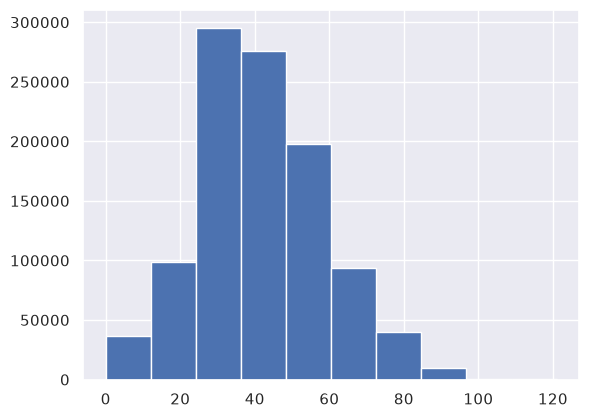

In [ ]:
data["AGE"].hist()

У нас достаточно данных, чтобы поделить пациентов на следующие возрастные группы.
- 0–17
- 18–29
- 30–39
- 40–49
- 50–59
- 60–69
- 70–79
- 80+

Теперь осталось понять, что делать с пропущенными значениями. Посмотрим как много у нас пропущенных.

In [ ]:
# Boolean-признаки: 1 = «да», 2 = «нет», а 97/98/99 = пропущенные данные.
BINARY_COLS = [
    'PNEUMONIA', 'PREGNANT', 'DIABETES', 'COPD', 'ASTHMA', 'INMSUPR',
    'HIPERTENSION', 'CARDIOVASCULAR', 'RENAL_CHRONIC', 'OTHER_DISEASE',
    'OBESITY', 'TOBACCO', 'USMER', 'INTUBED', 'ICU',
]

# Считаем пропуски по всем столбцам исходных данных
raw = initData.copy()
missing_counts = {}
for col in raw.columns:
    # настоящие NaN
    is_nan = raw[col].isna()
    # коды-заглушки 97/98/99 (актуально для boolean-признаков)
    is_sentinel = raw[col].isin([97, 98, 99]) if col in BINARY_COLS else pd.Series(False, index=raw.index)
    missing_counts[col] = int((is_nan | is_sentinel).sum())

missing_df = (
    pd.Series(missing_counts, name='пропусков')
    .sort_values(ascending=False)
    .to_frame()
)

missing_df['доля, %'] = (missing_df['пропусков'] / len(raw) * 100).round(2)
print('Пропущенные значения по столбцам (NaN + коды 97/98/99):')
print(missing_df)
print(f'\nВсего строк: {len(raw)}')

Пропущенные значения по столбцам (NaN + коды 97/98/99):
                      пропусков  доля, %
ICU                      856032    81.64
INTUBED                  855869    81.62
PREGNANT                 527265    50.28
PNEUMONIA                 16003     1.53
OTHER_DISEASE              5045     0.48
INMSUPR                    3404     0.32
DIABETES                   3338     0.32
TOBACCO                    3220     0.31
HIPERTENSION               3104     0.30
CARDIOVASCULAR             3076     0.29
OBESITY                    3032     0.29
RENAL_CHRONIC              3006     0.29
COPD                       3003     0.29
ASTHMA                     2979     0.28
DATE_DIED                     0     0.00
SEX                           0     0.00
MEDICAL_UNIT                  0     0.00
USMER                         0     0.00
PATIENT_TYPE                  0     0.00
AGE                           0     0.00
CLASIFFICATION_FINAL          0     0.00

Всего строк: 1048575


## Какие признаки оставляем
Оставляем признаки с наименьшим количеством пропусков. Будем исследовать 8 переменных, 7 - признаки, которые предположительно сильнее всего влияют на вероятность летального исхода от ковида и 1 - факт летального исхода.

In [46]:
import pandas as pd
ALIVE_DATE = '9999-99-99'
USED_COLUMNS = ("SEX", "AGE", "DIABETES", "HIPERTENSION", "CARDIOVASCULAR", "COPD", "PNEUMONIA", "DATE_DIED")
BINARY_COLUMNS = ("SEX", "DIABETES", "HIPERTENSION", "CARDIOVASCULAR", "COPD", "PNEUMONIA")
AGE_BINS = [0, 18, 30, 40, 50, 60, 70, 80, float('inf')]
def prepareCovid(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df[list(USED_COLUMNS)]
    #transforming date of death to fact of lethal outcome 
    df['DEATH'] = (df['DATE_DIED'] != ALIVE_DATE).astype(int)
    df = df.drop(columns=['DATE_DIED'])
    #transform to binary
    for c in BINARY_COLUMNS:
        df[c] = df[c].replace({1:0, 2:1})
        df[c] = df[c].where(df[c].isin([0, 1]))
    #discretization of age
    df["AGE"] = pd.cut(df["AGE"], labels=range(len(AGE_BINS)-1), bins=AGE_BINS, right=False, include_lowest=True)
    df = df.dropna()
    df["AGE"] = df["AGE"].astype(int)
    return df
preparedData = prepareCovid(initData) 
preparedData.head()
print(preparedData.shape)

(1028345, 8)


## Редкие категории
Посмотрим на доли каждого значения каждого признака в датасете.

In [47]:
# Доли каждого значения в каждой переменной
rows = []
for col in preparedData.columns:
    vc = preparedData[col].value_counts(normalize=True).sort_index()
    for val, share in vc.items():
        rows.append({
            "признак": col,
            "значение": val,
            "количество": int(preparedData[col].value_counts().loc[val]),
            "доля, %": round(share * 100, 2),
        })

share_table = pd.DataFrame(rows)[["признак", "значение", "количество", "доля, %"]]
share_table


,признак,значение,количество,"доля, %"
0,SEX,0.0,514647,50.05
1,SEX,1.0,513698,49.95
2,AGE,0.0,49583,4.82
3,AGE,1.0,196367,19.10
4,AGE,2.0,246121,23.93
5,AGE,3.0,220408,21.43
6,AGE,4.0,162247,15.78
7,AGE,5.0,87948,8.55
8,AGE,6.0,44188,4.30
9,AGE,7.0,21483,2.09


Мы можем увидеть, что у нас мало пациентов с сердечно-сосудистыми заболеваниями, пациентов с COPD, пациентов младше 18 и старше 60. В целом есть представители каждой категории.